### Structured and extendable simulation environment
This is version two of the simulation code proposed above. The main focus lies on a better evaluation of different control system codes and an improved generation of real sensor data. We also instroduce a more structured logging approach for analysing and visualising the simulation results.

In [130]:
import math
import time
import numpy as np

import scipy.integrate as itg
from typing import Callable, TypeAlias
from collections.abc import Sequence

import helpers
import constants

## Sensor settings
SENSOR_SETTING_VEL_READ_NOISEFACTOR = 0.2
SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR = 0.3


flightLogs: list[FlightLogEntry] = []

# The data our algorithm predicts and collects (AirBrakeSoftwareData)
class ABSData:
    bodyCdEstimate: float
    currentStateApogeePrediction: float
    sensorSpeed: float
    filteredSpeed: float
    sensorHeight: float
    filteredHeight: float

    def __init__(self,cdEstimate, currentApogeePreciction,sensorSpeed, filterSpeed, sensorHeight, filterHeight):
        self.bodyCdEstimate = cdEstimate
        self.currentStateApogeePrediction = currentApogeePreciction
        self.sensorSpeed = sensorSpeed
        self.filteredSpeed = filterSpeed
        self.sensorHeight = sensorHeight
        self.filteredHeight = filterHeight

# The actual simulated data
class FlightLogEntry:
    timestamp: int
    height: float
    verticalVelocity: float
    airbrakeExtension: float

    controlSoftwareData: ABSData
    absExecutionTime: float

    def __init__(self,ts,height,verticalVel, airbrakeExt, absStruct,absExecutionTime):
        self.timestamp = ts
        self.height = height
        self.verticalVelocity = verticalVel
        self.airbrakeExtension = airbrakeExt
        self.controlSoftwareData = absStruct
        self.absExecutionTime = absExecutionTime


def getSensorReading(actualValue: float, relativeNoise: float, bias: float, drift: float, t: float) -> float:
    return actualValue + bias + (drift * t) + np.random.normal(0.0, relativeNoise, 1)

"""
    @brief The function that will be called from the simulation looop each iteration.
    @param timeSinceMotorStart [float]
    @param verticalHeight [float]
    @param verticalVelocity [float]
    @return Extension state of the airbrake [float] as well as the [ABSData] for logging.
"""
AirbrakeControlSoftwareCallback: TypeAlias = Callable[[float, float, float], tuple[float, ABSData]]


"""
    @brief Runs the simulation.
    @param targetApogee [float]
    @param t0 Simulation start time [float]
    @param h0 initialHeight [float]
    @param t0 initialVelocity [float]
    @param controlSoftware [AirbrakeControlSoftwareCallback]
    @return List of the LogEntries [list<FlightLogEntry>]
"""
def runSimulation(targetApogee,t0, h0, v0, controlSoftware:AirbrakeControlSoftwareCallback) -> Sequence[FlightLogEntry]:
    global flightLogs,SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR,SENSOR_SETTING_VEL_READ_NOISEFACTOR
    flightLogs = []

    def dynamicSystem(t,x_data):
        global flightLogs
        x = x_data[0]
        v = x_data[1]

        dx_dt = v    # x' = v
        currentAltitudeAirDensity = helpers.airDensityFromHeight(x)

        # We can make this a function of height/velocity to simulate oscillations (maybe between 85° and 95°)
        crossSectionalArea = (math.pi * (constants.ROCKET_OUTER_DIAMETER_M/2)**2) # m²

        # F_D = 1/2 p A C_d v²
        bodyDragForce = (1/2) * currentAltitudeAirDensity * crossSectionalArea * constants.ROCKET_DEFAULT_CD * (v**2)

        # Generate sensor data, run and time the control algorithm.
        heightSensorReading = getSensorReading(x,SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR,0.0,0.0, t)
        velocitySensorReading = getSensorReading(v,SENSOR_SETTING_VEL_READ_NOISEFACTOR, 0,0, t)

        timeBeforeExec = time.perf_counter()
        (airbrakeExtension, absUnitLog) = controlSoftware(t,heightSensorReading,velocitySensorReading)
        absExecutionTime = time.perf_counter() - timeBeforeExec

        if (absUnitLog is None):
            absUnitLog = ABSData(cdEstimate=0,currentApogeePreciction=0,sensorSpeed=velocitySensorReading,filterSpeed=velocitySensorReading,sensorHeight=heightSensorReading,filterHeight=heightSensorReading)
       
        logEntry = FlightLogEntry(t,x,v,airbrakeExtension,absUnitLog,absExecutionTime)
        flightLogs.append(logEntry)

        # Use the calculated extension to finish simulation step

        airbrakeDragForce = helpers.airbrakeAdditionalDragForce(airbrakeExtension,constants.ROCKET_AIRBRAKE_DEFAULT_CD,v,currentAltitudeAirDensity)
        dy_dt = -9.81 - (bodyDragForce + airbrakeDragForce)/constants.ROCKET_BURNOUT_MASS
        return [dx_dt, dy_dt]

    solver = itg.RK45(dynamicSystem, t0, [h0, v0], 200, max_step=0.005)
    stepCount = 0
    while solver.status == "running":
        solver.step()
        stepCount += 1

        # Checking of y = 0 is hit to terminate simulation
        if solver.y[0] <= 0:
            break

    print(f"Solver status: {solver.status}. Steps: {stepCount}")
    return flightLogs


## Testing the simulation harness

In [133]:
import constants
# [float, float, float], tuple[float, ABSData]
def airbrakeControlSoftware(t: float, h: float, v: float) -> tuple[float,ABSData]:
    unitLogEntry = ABSData(cdEstimate=0,currentApogeePreciction=100,sensorSpeed=10,filterSpeed=10,sensorHeight=10,filterHeight=10)
    return (0.0,None)

flightData:Sequence[FlightLogEntry] = runSimulation(600,constants.SIM_T0,constants.SIM_T0_HEIGHT,constants.SIM_T0_VELOCITY,airbrakeControlSoftware)

Solver status: running. Steps: 5228


Apogee: 1005.1228029195495


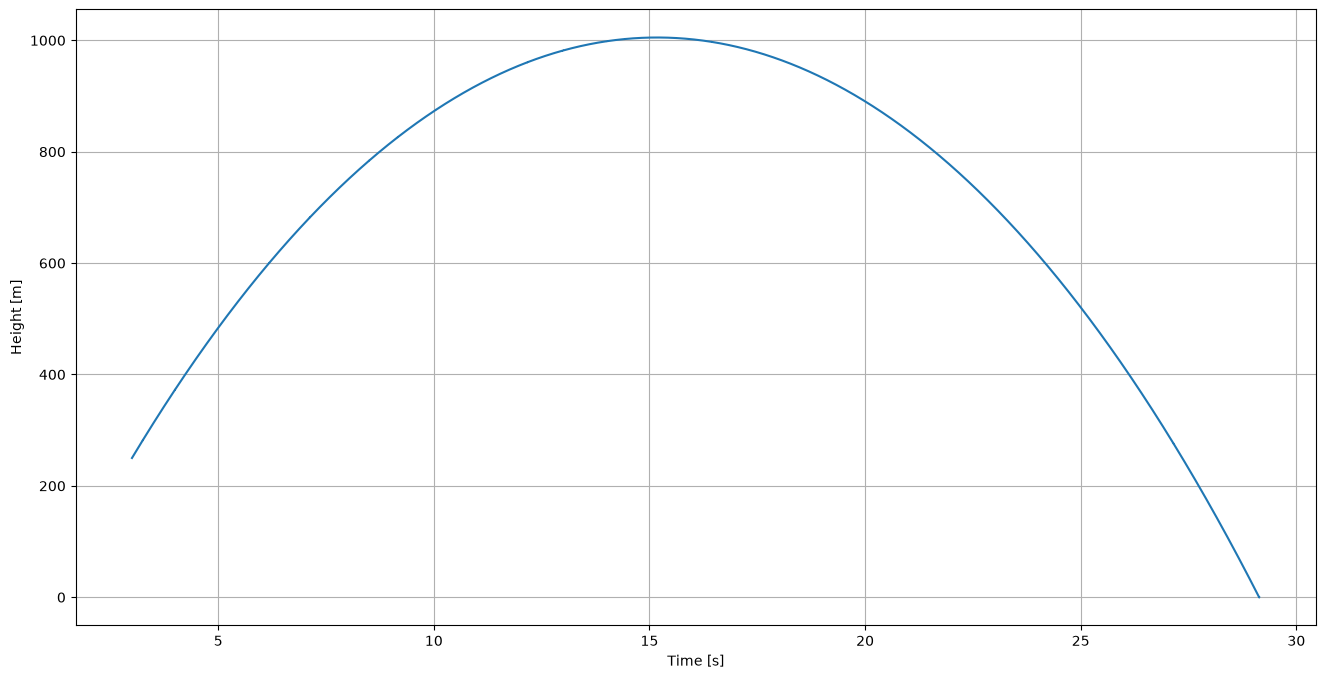

In [134]:
from matplotlib import pyplot as plt

# Analysing the data
t = np.array([i.timestamp for i in flightData])
h = np.array([i.height for i in flightData])

print(f"Apogee: {max(h)}")

plt.plot(t,h)
plt.ylabel("Height [m]")
plt.xlabel("Time [s]")
plt.grid(True)
plt.show()


### ABS control algorithm concept

My approach for realtime adjustments to the airbrakes uses several control loops, predictions and phases.

It starts off with a short phase that gives us an estimate of the now defined drag term $dragArea$ that combines the drag coefficient as well as the crosssectional area that experiences the incoming air. The combined term is chosen as a composite, to account for a change in $C_d$ due to differences in turbulence and a changing crosssectional area because of tilting away from 90°. The $dragArea$ is automatically adjusted using a g-h-filter in the first phase and for now afterwards assumed to be constant.

In phase two of the ABS system we do the following in each iteration:

- estimating the the $dragArea$ as a function of the airbrake extension
- using this $DA$ to analytically calculate the apogee we will reach if the airbrakes stayed at this level
- calculate the error from the calculated to the target apogee and adjust the airbrake extension in a PD loop to get closer to target

In [147]:
import math
import helpers
import helpers as helper
from importlib import reload
reload(helper)
from typing import Optional, Sequence


NO_AIRBRAKE_PHASE_T_END = 3.5
SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR = 0.0
SENSOR_SETTING_VEL_READ_NOISEFACTOR = 0.1


initalCdAreaGuess = (constants.ROCKET_OUTER_DIAMETER_M/2)**2 * math.pi * constants.ROCKET_DEFAULT_CD

lastTimeStep = constants.SIM_T0
lastVel = constants.SIM_T0_VELOCITY # without any noise for now

bodyCdAreaFilter = helper.GHFilterDeltaT(x0=initalCdAreaGuess,dx0=0,g=0.2,h=0.2)
velocityFilter = helper.GHFilterDeltaT(x0=constants.SIM_T0_VELOCITY,dx0=-10,g=0.01,h=0.008)

# Second order filter, since we are accelerating
heightFilter = helper.GHKFilterDeltaT(x0=constants.SIM_T0_HEIGHT,dx0=constants.SIM_T0_VELOCITY,ddx0=0,g=0.1,h=0.3,k=0.01) # this has to be second order


def airbrakeControlSoftware(t: float, h: float, v: float) -> tuple[float,Optional[ABSData]]:
    global lastTimeStep, lastVel, bodyCdAreaFilter

    # Ensure forward time direction
    if t - lastTimeStep < 0:
        print("going back in time")
        lastTimeStep = t
        lastVel = v

        return (0, None)

    if t <= NO_AIRBRAKE_PHASE_T_END:
        # Setting up for filter code
        deltaTime = t - lastTimeStep


        # Filtering all the data
        heightFilter.update(deltaTime,h)
        velocityFilter.update(deltaTime,v)

        filtered_h = heightFilter.x
        filtered_v = velocityFilter.x


        ## Using the second derivate of height and the first of velocity to get acceleration estimate
        deltaV = (0.7 * velocityFilter.dx) + (0.3 * heightFilter.ddx)


        estimatedAirDensity = helper.airDensityFromHeight(h[0])

        Cd_guess = (2 * constants.ROCKET_BURNOUT_MASS * deltaV) / (estimatedAirDensity * filtered_v**2)
        Area_guess = (math.pi * ((constants.ROCKET_OUTER_DIAMETER_M/2)**2)) # m²
        CdA = Cd_guess * Area_guess

        # Estimate the bodies C_D * area
        # (cda_estimate, _) = bodyCdAreaFilter.update(deltaTime,CdA)
        lastTimeStep = t


        data = ABSData(cdEstimate=CdA,currentApogeePreciction=0,sensorSpeed=v,filterSpeed=filtered_v,sensorHeight=h,filterHeight=filtered_h)
        return (0, data)
    else:
        return (0, None)

flightData:Sequence[FlightLogEntry] = runSimulation(960,constants.SIM_T0,constants.SIM_T0_HEIGHT,constants.SIM_T0_VELOCITY, airbrakeControlSoftware)

going back in time
Solver status: running. Steps: 5228


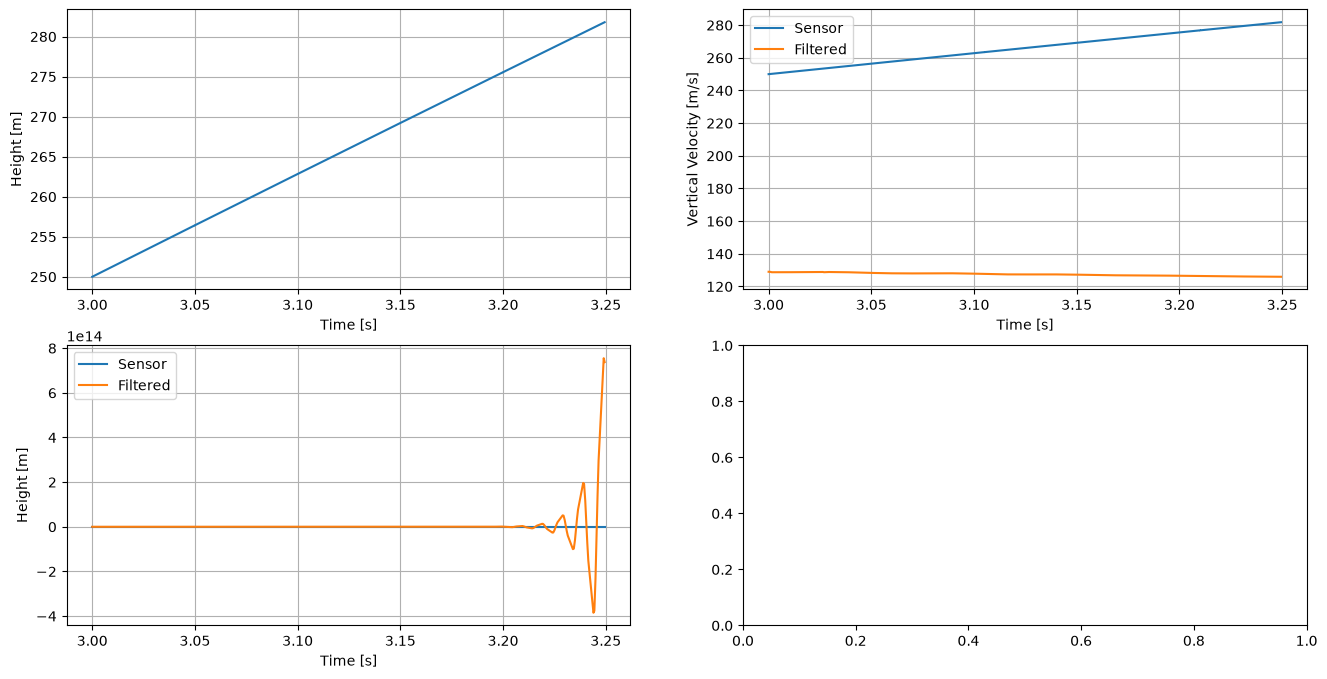

In [148]:
from matplotlib import pyplot as plt

windowStart = 0
windowEnd = 300

# Sort the flight Data according to timestamp
flightData.sort(key=lambda x: x.timestamp)


t = [i.timestamp for i in flightData[windowStart:windowEnd]]
h = [i.height for i in flightData[windowStart:windowEnd]]
v = [i.verticalVelocity for i in flightData[windowStart:windowEnd]]
vf = [i.controlSoftwareData.filteredSpeed for i in flightData[windowStart:windowEnd]]
sh = [i.controlSoftwareData.sensorSpeed for i in flightData[windowStart:windowEnd]]
cd = [i.controlSoftwareData.bodyCdEstimate for i in flightData[windowStart:windowEnd]]
fh = [i.controlSoftwareData.filteredHeight for i in flightData[windowStart:windowEnd]]
sh = [i.controlSoftwareData.sensorHeight for i in flightData[windowStart:windowEnd]]

fig = plt.figure()
ax = fig.subplots(2,2)


ax[0,0].plot(t,h)
ax[0,0].set_ylabel("Height [m]")
ax[0,0].set_xlabel("Time [s]")
ax[0,0].grid(True)

ax[0,1].plot(t,sh,label="Sensor")
ax[0,1].plot(t,vf,label="Filtered")
ax[0,1].set_ylabel("Vertical Velocity [m/s]")
ax[0,1].set_xlabel("Time [s]")
ax[0,1].grid(True)
ax[0,1].legend()

# Add height and filtered height
ax[1,0].plot(t,sh,label="Sensor")
ax[1,0].plot(t,fh,label="Filtered")
ax[1,0].set_ylabel("Height [m]")
ax[1,0].set_xlabel("Time [s]")
ax[1,0].grid(True)
ax[1,0].legend()

# ax[1,0].plot(t,s,label="Sensor")
# ax[1,0].plot(t,vf,label="Filtered")
# ax[1,0].set_ylabel("Vertical Velocity [m/s]")
# ax[1,0].set_xlabel("Time [s]")
# ax[1,0].grid(True)
# ax[1,0].legend()

# ax[1,1].plot(t,cd)
# ax[1,1].set_ylabel("Estimated C_D * Area [m²]")
# ax[1,1].set_xlabel("Time [s]")
# ax[1,1].grid(True)